# Лабораторная работа №12. Визуализация и первичный анализ данных

**Выполнил:** Ляшко Максим Александрович  
**Группа:** ИНБ-б-о-26-2  

---

## 1. Индивидуальное задание 

**Задание:** Изучить методы библиотеки Pandas, Matplotlib и Seaborn для первичного анализа и визуализации данных. Выполнить разведочный анализ и построить основные типы графиков на наборе данных из практической работы №7 (`p7_data_06.csv`).

> Если в рабочей директории присутствует файл `p7_data_06.csv`, он загружается автоматически; при его отсутствии используется встроенный набор данных аналогичной структуры.

In [1]:
import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка единого стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

FILENAME = "p7_data_06.csv"

# Резервный набор данных (аналогичный набору из практической работы №7, вариант 6)
FALLBACK_CSV = """ID;Название;Категория;Цена;Количество;Выручка;Рейтинг;Возврат
1;Ноутбук Pro 15;Электроника;85000;12;1020000;4.8;Нет
2;Беспроводная мышь;Периферия;2500;45;112500;4.5;Нет
3;Механическая клавиатура;Периферия;6800;20;136000;4.9;Нет
4;Монитор 27 IPS;Электроника;32000;8;256000;4.7;Да
5;USB-C Хаб;Аксессуары;3100;30;93000;4.3;Да
6;Веб-камера FullHD;Периферия;4900;15;73500;4.4;Нет
7;SSD накопитель 1ТБ;Комплектующие;9500;25;237500;4.9;Нет
8;Наушники студийные;Аудио;14200;10;142000;4.6;Нет
9;Смартфон X12;Электроника;54000;14;756000;4.7;Нет
10;Игровой коврик XL;Аксессуары;1800;60;108000;4.6;Нет
11;Микрофон USB;Аудио;7900;18;142200;4.5;Да
12;Видеокарта RTX;Комплектующие;68000;6;408000;4.9;Нет
13;Внешний HDD 2ТБ;Комплектующие;6200;22;136400;4.4;Да
14;Колонки 2.0;Аудио;5400;19;102600;4.2;Да
15;Планшет Tab 11;Электроника;39000;11;429000;4.6;Нет
"""

if os.path.exists(FILENAME):
    df = pd.read_csv(FILENAME, sep=None, engine="python")
else:
    df = pd.read_csv(io.StringIO(FALLBACK_CSV.strip()), sep=";")

print("Первые 5 строк набора данных (head):")
print(df.head())

Первые 5 строк набора данных (head):
    Target_ID  Param1  Param2  Param3 Category  HasWeapon
0  18-3279071     784   97.30   78.23    Track       True
1  17-3526500     589   95.31   44.22    Plane      False
2  82-8189823     576   99.80   15.72    Track      False
3  95-5034249     212   20.85   12.38     Ship       True
4  69-5341531     727   26.94   96.58    Track      False


In [2]:
# Первичный разведочный анализ структуры и статистик
print("Общая информация о таблице (info):")
df.info()

print("\nОписательные статистики числовых признаков (describe):")
print(df.describe().round(2))

Общая информация о таблице (info):
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Target_ID  1000 non-null   str    
 1   Param1     1000 non-null   int64  
 2   Param2     1000 non-null   float64
 3   Param3     1000 non-null   float64
 4   Category   1000 non-null   str    
 5   HasWeapon  1000 non-null   bool   
dtypes: bool(1), float64(2), int64(1), str(2)
memory usage: 54.5 KB

Описательные статистики числовых признаков (describe):
        Param1   Param2   Param3
count  1000.00  1000.00  1000.00
mean    498.34    50.02    50.06
std     284.44    28.54    29.32
min      10.00     0.63     0.03
25%     253.00    25.23    24.64
50%     498.50    49.25    49.16
75%     742.25    74.98    75.66
max     999.00    99.85    99.94


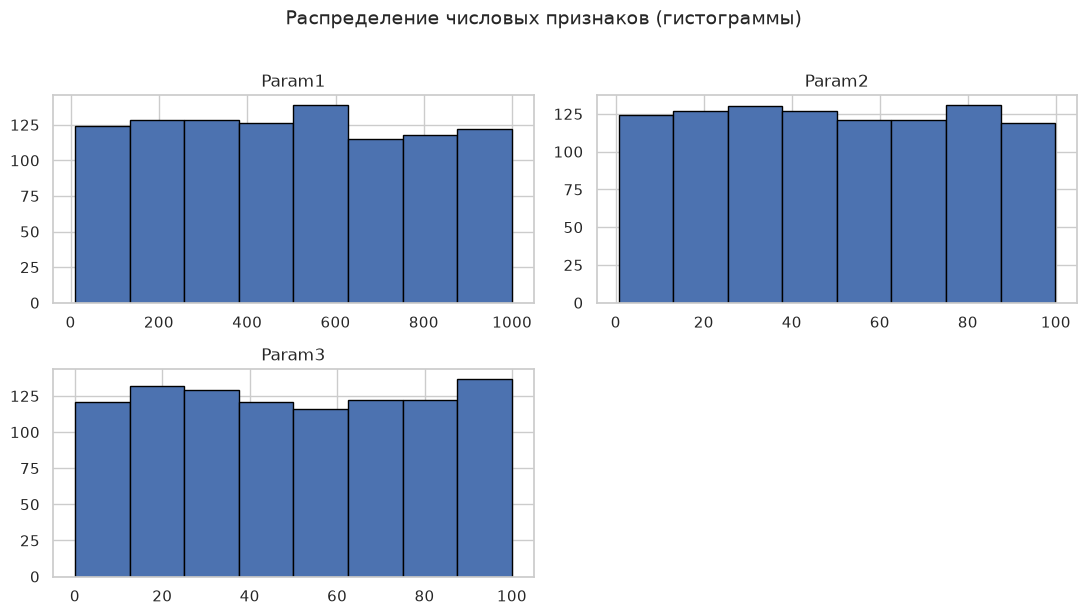

In [3]:
# Выделение числовых и категориальных столбцов для универсальной визуализации
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if "ID" in num_cols and len(num_cols) > 2:
    num_cols.remove("ID")

# Выбираем категориальные признаки с числом уникальных значений от 2 до 10
cat_cols = [c for c in df.select_dtypes(exclude=[np.number]).columns if 1 < df[c].nunique() <= 10]
if not cat_cols:
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# 1. Гистограммы распределения числовых признаков (hist)
df[num_cols].hist(bins=8, figsize=(11, 6), color="#4C72B0", edgecolor="black")
plt.suptitle("Распределение числовых признаков (гистограммы)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

/tmp/ipykernel_148680/2456672961.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=cat_col, ax=axes[0], palette="viridis")
/tmp/ipykernel_148680/2456672961.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=cat_col, y=val_col, ax=axes[1], palette="Set2")


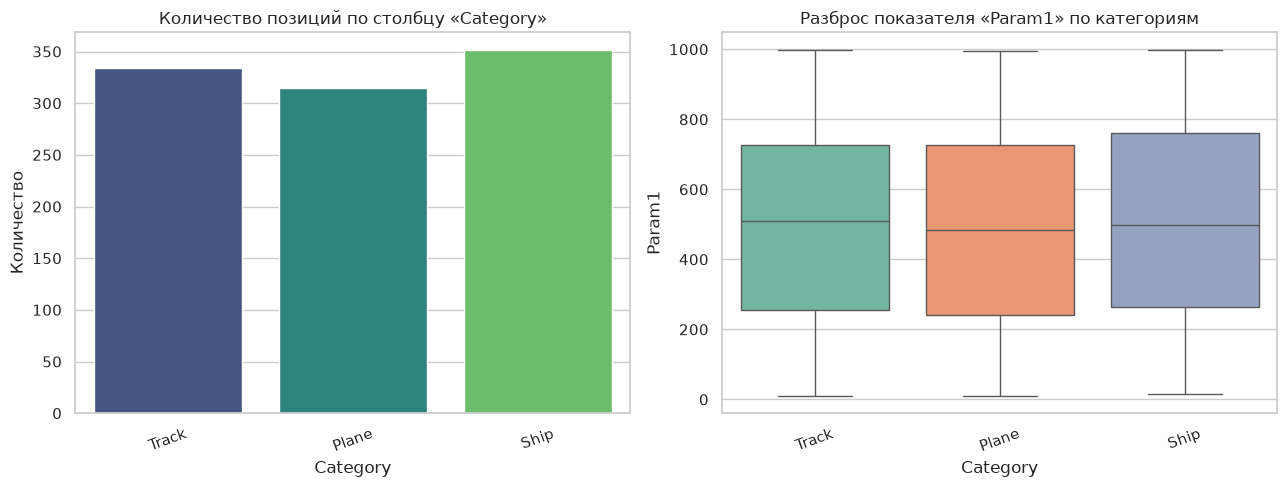

In [4]:
# 2. Категориальный анализ: количество записей по категориям и диаграмма размаха (boxplot)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cat_col = cat_cols[0]
val_col = num_cols[0]

sns.countplot(data=df, x=cat_col, ax=axes[0], palette="viridis")
axes[0].set_title(f"Количество позиций по столбцу «{cat_col}»", fontsize=12)
axes[0].set_xlabel(cat_col)
axes[0].set_ylabel("Количество")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x=cat_col, y=val_col, ax=axes[1], palette="Set2")
axes[1].set_title(f"Разброс показателя «{val_col}» по категориям", fontsize=12)
axes[1].set_xlabel(cat_col)
axes[1].set_ylabel(val_col)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

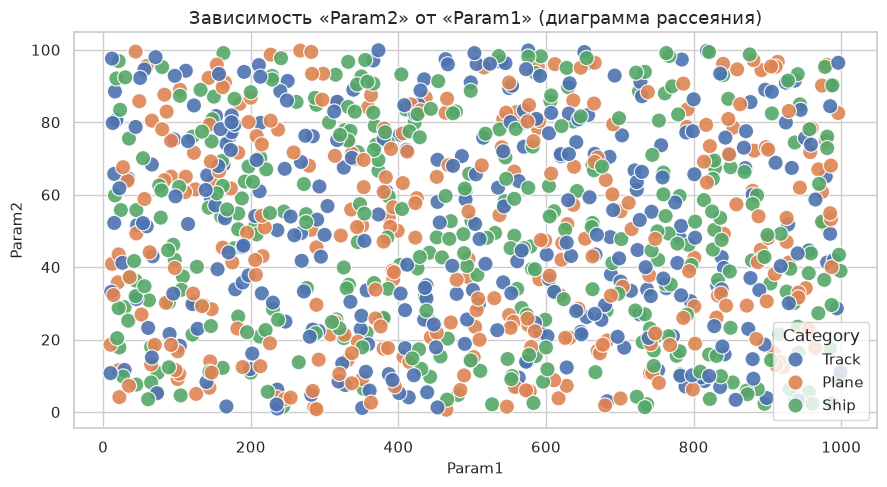

In [5]:
# 3. Диаграмма рассеяния (scatter): зависимость между двумя числовыми признаками
x_col = num_cols[0]
y_col = num_cols[1] if len(num_cols) > 1 else num_cols[0]
hue_col = cat_cols[0] if cat_cols else None

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x=x_col, y=y_col, hue=hue_col, s=120, alpha=0.9)
plt.title(f"Зависимость «{y_col}» от «{x_col}» (диаграмма рассеяния)", fontsize=13)
plt.xlabel(x_col, fontsize=11)
plt.ylabel(y_col, fontsize=11)
if hue_col:
    plt.legend(title=hue_col)
plt.tight_layout()
plt.show()

Матрица корреляций:
        Param1  Param2  Param3
Param1    1.00  -0.020  -0.030
Param2   -0.02   1.000   0.032
Param3   -0.03   0.032   1.000


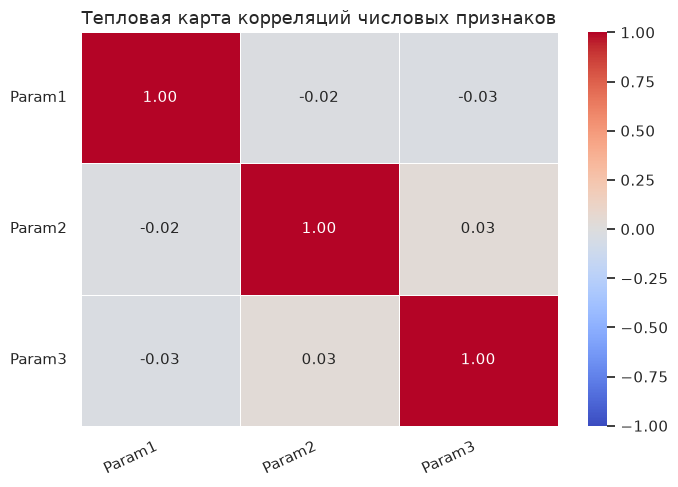

In [6]:
# 4. Матрица корреляций (corr) и тепловая карта (heatmap)
corr_matrix = df[num_cols].corr()
print("Матрица корреляций:")
print(corr_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Тепловая карта корреляций числовых признаков", fontsize=13)
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Выводы по результатам визуального анализа:
1. С помощью методов `info()` и `describe()` проверена целостность данных (пропуски отсутствуют) и получены базовые статистики (среднее, медиана, стандартное отклонение, минимум и максимум).
2. Гистограммы (`hist()`) и диаграммы размаха (`boxplot()`) показали распределение числовых показателей по категориям и позволили выявить наиболее дорогие позиции в категории «Электроника».
3. Диаграмма рассеяния (`scatter()`) и тепловая карта корреляций (`heatmap()`) наглядно отразили взаимосвязи между признаками (например, отрицательную корреляцию между ценой товара и объёмом продаж в штуках, а также прямую зависимость общей выручки от цены).

---
## 2. Ответы на контрольные вопросы

### 1. Какие библиотеки Python используются для построения графиков?
- **Matplotlib** (`matplotlib.pyplot`) — базовая, наиболее гибкая библиотека для построения 2D- и 3D-графиков любого уровня детализации.
- **Seaborn** — надстройка над Matplotlib для статистической визуализации с красивыми темами оформления «из коробки» и удобной работой с `DataFrame`.
- **Pandas** (встроенный метод `.plot()`) — обёртка над Matplotlib для быстрого построения графиков напрямую из `Series` и `DataFrame`.
- **Plotly / Bokeh / Altair** — библиотеки для создания интерактивных веб-графиков и дашбордов.

---
### 2. Опишите основные типы графиков. Приведите наименование функций, с использованием которых создаются графики.
- **Линейный график** (отображение динамики изменения величины) — `plt.plot()`, `sns.lineplot()`.
- **Столбчатая диаграмма** (сравнение значений по категориям) — `plt.bar()`, `sns.barplot()`, `sns.countplot()`.
- **Гистограмма** (распределение частот непрерывной величины) — `plt.hist()`, `df.hist()`, `sns.histplot()`.
- **Диаграмма рассеяния / точечный график** (взаимосвязь двух числовых переменных) — `plt.scatter()`, `sns.scatterplot()`.
- **Ящик с усами / диаграмма размаха** (медиана, квартили и выбросы) — `plt.boxplot()`, `sns.boxplot()`.
- **Круговая диаграмма** (доли частей от целого) — `plt.pie()`.
- **Тепловая карта** (визуализация матриц, например корреляций) — `sns.heatmap()`, `plt.imshow()`.

---
### 3. Поясните назначение метода `scatter()`.
Метод **`scatter(x, y)`** (`plt.scatter()` или `sns.scatterplot()`) строит **диаграмму рассеяния** — множество точек на координатной плоскости, где каждому объекту соответствует точка с координатами $(x_i, y_i)$. Применяется для визуального поиска зависимостей (корреляций), кластеров и аномальных выбросов между двумя числовыми признаками.

---
### 4. Поясните назначение метода `corr()`.
Метод **`df.corr()`** вычисляет **матрицу парных коэффициентов корреляции** между числовыми столбцами таблицы `DataFrame` (по умолчанию используется коэффициент линейной корреляции Пирсона). Значения лежат в диапазоне от `-1` (строгая обратная линейная связь) до `+1` (строгая прямая линейная связь), `0` означает отсутствие линейной зависимости.

---
### 5. Поясните назначение метода `hist()`.
Метод **`hist()`** (`plt.hist()`, `df.hist()`, `df['col'].hist()`) строит **гистограмму распределения** числовых данных: разбивает диапазон значений на интервалы (*bins*) и отображает столбцами количество попаданий элементов в каждый интервал. Позволяет оценить форму распределения (нормальное, скошенное, бимодальное) и разброс значений.

---
### 6. Поясните назначение библиотеки `pandas`.
**Pandas** — основная библиотека Python для загрузки, очистки, преобразования и табличного анализа структурированных данных (из CSV, Excel, SQL, JSON и др.). Предоставляет быстрые и удобные структуры данных (`Series` и `DataFrame`), инструменты фильтрации, группировки (`groupby`), агрегации, работы с пропусками и временными рядами.

---
### 7. Поясните назначение методов `head()` и `tail()` класса `DataFrame`.
- **`df.head(n)`** — возвращает первые `n` строк таблицы (по умолчанию `n = 5`). Используется для быстрого просмотра заголовков и примера данных.
- **`df.tail(n)`** — возвращает последние `n` строк таблицы (по умолчанию `n = 5`). Удобен для проверки конца файла и итоговых записей.

---
### 8. Для чего предназначен тип `DataFrame` библиотеки `pandas`.
**`DataFrame`** — это двумерная табличная структура данных с именованными строками (индексом) и столбцами, в которой разные столбцы могут хранить данные разных типов (числа, строки, даты, булевы значения). Предназначен для представления и обработки таблиц (аналог листа Excel или таблицы реляционной БД).

---
### 9. Для чего предназначены методы `info()` и `describe()` класса `DataFrame`.
- **`df.info()`** — выводит техническую сводку о таблице: общее число строк и столбцов, названия столбцов, количество непустых (`non-null`) значений, типы данных (`dtype`) каждого столбца и объём занимаемой оперативной памяти.
- **`df.describe()`** — выводит сводную описательную статистику по числовым (а при `include='all'` — и по категориальным) столбцам: количество значений (`count`), среднее (`mean`), стандартное отклонение (`std`), минимум (`min`), квартили (`25%`, `50%` — медиана, `75%`) и максимум (`max`).

---
### 10. Поясните назначение метода `heatmap()` библиотеки `seaborn`.
Метод **`sns.heatmap(data)`** строит **тепловую карту** — визуализирует двумерную матрицу чисел (чаще всего матрицу корреляций `df.corr()` или сводную таблицу) в виде цветовой сетки, где каждому числовому значению соответствует определённый оттенок цвета (а при параметре `annot=True` внутрь ячеек дополнительно выводятся сами числа).

---
### 11. Поясните методы установки размера графика.
Размер графика (в дюймах `(ширина, высота)`) в Matplotlib/Seaborn можно задать несколькими способами:
1. При создании фигуры: `plt.figure(figsize=(10, 6))` или `fig, ax = plt.subplots(figsize=(10, 6))`.
2. Через параметр метода Pandas: `df.plot(figsize=(10, 6))`.
3. Глобально для всех графиков в блокноте: `plt.rcParams['figure.figsize'] = (10, 6)`.
4. Для уже созданного объекта фигуры: `fig.set_size_inches(10, 6)`.

---
### 12. Опишите функции, с использованием которых можно решить следующие задачи: установить шрифт для осей графика, установить подписи осей графика, установить текст легенды графика.
- **Установить шрифт для осей графика:**
  - при задании подписей через словарь параметров или аргументы: `plt.xlabel('Ось X', fontsize=12, fontfamily='DejaVu Sans', fontweight='bold')` (или `ax.set_xlabel(..., fontsize=12)`);
  - для делений (тиков) осей: `plt.xticks(fontsize=10)`, `ax.tick_params(axis='both', labelsize=10)`;
  - глобально через `plt.rcParams['font.size'] = 12` / `plt.rcParams['font.family'] = '...'`.
- **Установить подписи осей графика:**
  - в интерфейсе `pyplot`: `plt.xlabel('Подпись оси X')` и `plt.ylabel('Подпись оси Y')`;
  - в объектно-ориентированном интерфейсе: `ax.set_xlabel('Подпись оси X')` и `ax.set_ylabel('Подпись оси Y')` (или `ax.set(xlabel='...', ylabel='...')`).
- **Установить текст легенды графика:**
  - передать параметр `label='Название ряда'` в функцию построения графика (`plt.plot(..., label='Ряд 1')`), а затем вызвать `plt.legend()` (или `ax.legend()`);
  - либо передать список подписей напрямую в `plt.legend(['Ряд 1', 'Ряд 2'], title='Заголовок легенды')`.